<a name='1'></a>
<h1 style="text-align: center; font-size: 36px;">Dual-Individual Genetic Algorithm with L2 Regularization and Dropout for Enhanced Model Generalization
Training of Multi-Layer Neural Networks</h1>

## Table of Contents
- [1 - Dataset](#1-dataset)
- [2 - Forward Propagation with Dropout & L2 Regularization](#2-forward-propagation-with-dropout-l2-regularization)
- [3 - Initialize all parameters](#4-initialize-all-parameters)
- [4 - Creating new solutions](#5-creating-new-solutions)
- [5 - Pareto optimization](#6-pareto-optimization)
- [6 - Pairing and Mutation](#7-pairing-and-mutation)
- [7 - Combining two offspring](#8-combining-two-offspring)
- [8 - Anabolism Process](#9-anabolism-process)
- [9 - Train the Model](#10-train-the-model)

<h3 id="1-dataset">1 - Dataset</h3>



  This dataset is part of Andrew Ng’s renowned deep learning course, offering a hands-on introduction to building neural networks from scratch using logistic regression. We highly recommend taking the course itself and  download the dataset directly from the course platform (e.g., Coursera). (https://www.coursera.org/specializations/deep-learning)

In [1]:
import time
import random
import numpy as np
import copy
import h5py
import matplotlib.pyplot as plt
import scipy
from PIL import Image
from scipy import ndimage
from dnn_app_utils_v3 import *
from public_tests import *
from copy import deepcopy  # Import deepcopy explicitly
%matplotlib inline
plt.rcParams['figure.figsize'] = (5.0, 4.0) # set default size of plots
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

%load_ext autoreload
%autoreload 2


<h3 id="2-forward-propagation-with-dropout-l2-regularization">2 - Forward Propagation with Dropout & L2 Regularization</h3>


<div align="center">
<img src="images/Forward_Propagation_with_Dropout_&_L2_Regularization.png" style="width:450px;height:550px;">
<caption><center><font color='purple'><b>Figure 1</b>: Forward Propagation with Dropout & L2 Regularization.</font></center></caption>

In [2]:
# ==================== BASIC FUNCTIONS ====================

def linear_forward(A, W, b):
    """
    Implement the linear part of a layer's forward propagation.

    Arguments:
    A -- activations from previous layer (or input data): (size of previous layer, number of examples)
    W -- weights matrix: numpy array of shape (size of current layer, size of previous layer)
    b -- bias vector, numpy array of shape (size of the current layer, 1)

    Returns:
    Z -- the input of the activation function, also called pre-activation parameter 
    """
    Z = np.dot(W, A) + b
    return Z

def relu(Z):
    """ReLU activation function."""
    return np.maximum(0, Z)

def sigmoid(Z):
    """Sigmoid activation function with numerical stability."""
    Z = np.clip(Z, -500, 500)  # Limit Z to prevent exp(-Z) from overflowing
    return 1 / (1 + np.exp(-Z))


# ==================== FORWARD PROPAGATION WITH DROPOUT ====================

def linear_activation_forward(A_prev, W, b, activation="relu", keep_prob=1.0, training=True):
    """
    Implement the forward propagation for the LINEAR->ACTIVATION layer with Dropout.

    Arguments:
    A_prev -- activations from previous layer (or input data): (size of previous layer, number of examples)
    W -- weights matrix: numpy array of shape (size of current layer, size of previous layer)
    b -- bias vector, numpy array of shape (size of the current layer, 1)
    activation -- the activation to be used in this layer, stored as a text string: "sigmoid" or "relu"
    keep_prob -- probability of keeping a neuron active during training (drop-out probability)
    training -- boolean, if True, apply dropout; if False, do not apply dropout

    Returns:
    A -- the output of the activation function, also called the post-activation value 
    """
    # 1. Compute linear and activation
    if activation == "sigmoid":
        Z = linear_forward(A_prev, W, b)
        A = sigmoid(Z)
    elif activation == "relu":
        Z = linear_forward(A_prev, W, b)
        A = relu(Z)
    else:
        raise ValueError("Unsupported activation function!")
        
    # 2. Apply Dropout 
    if training and keep_prob < 1.0:
        D = np.random.rand(A.shape[0], A.shape[1])     # Create random matrix D
        D = (D < keep_prob).astype(float)              # Convert to 0 or 1 (Mask)
        A = A * D                                      # Shut down some neurons randomly
        A = A / keep_prob                              # Inverted Dropout: scale up to maintain expected value
        
    return A


def L_model_forward(X, parameters, keep_prob=1.0, training=True):
    """
    Implement forward propagation for the [LINEAR->RELU]*(L-1)->LINEAR->SIGMOID computation.
    Supports Dropout for hidden layers.

    Arguments:
    X -- data, numpy array of shape (input size, number of examples)
    parameters -- output of initialize_parameters()
    keep_prob -- probability of keeping a neuron active (drop-out probability)
    training -- boolean, True for training phase, False for testing/inference phase

    Returns:
    AL -- activation value from the output (last) layer
    """
    A = X
    L = len(parameters) // 2  # number of layers in the neural network
    
    # 1. [LINEAR -> RELU] * (L-1) with Dropout
    for l in range(1, L):
        A_prev = A 
        A = linear_activation_forward(
            A_prev, 
            parameters["W" + str(l)], parameters["b" + str(l)], 
            activation="relu", 
            keep_prob=keep_prob, 
            training=training
        )
        
    # 2. LINEAR -> SIGMOID (Output layer does NOT apply Dropout)
    AL = linear_activation_forward(
        A, 
        parameters["W" + str(L)], parameters["b" + str(L)], 
        activation="sigmoid", 
        keep_prob=1.0,  # Always 1.0 for output layer
        training=training
    )
    
    # Clip AL to prevent log(0)
    AL = np.clip(AL, 1e-10, 1 - 1e-10)
    assert(AL.shape == (1, X.shape[1]))
  
    return AL


# ==================== COST COMPUTATION WITH L2 REGULARIZATION ====================

def compute_cost(AL, Y, parameters=None, lambd=0.0):
    """
    Implement the cost function with Cross-Entropy and optional L2 Regularization.
    
    Arguments:
    AL -- probability vector corresponding to your label predictions, shape (1, number of examples)
    Y -- true "label" vector, shape (1, number of examples)
    parameters -- dictionary containing model parameters (W1, b1, ..., WL, bL)
    lambd -- regularization hyperparameter (lambda), 0.0 means no L2 regularization
    
    Returns:
    cost -- cross-entropy cost + L2 regularization cost
    """
    m = Y.shape[1]
    
    # 1. Original Cross-entropy cost
    cost = (-1/m) * np.sum(np.multiply(np.log(AL), Y) + np.multiply(np.log(1-AL), (1-Y)))
    
    # 2. L2 Regularization cost
    if lambd > 0 and parameters is not None:
        L = len(parameters) // 2
        sum_W_squared = 0
        for l in range(1, L + 1):
            sum_W_squared += np.sum(np.square(parameters["W" + str(l)]))
        
        L2_regularization_cost = (lambd / (2 * m)) * sum_W_squared
        cost = cost + L2_regularization_cost
        
    cost = np.squeeze(cost)      # Make sure cost is a scalar
    
    return cost

<h3 id="3-outline-proposed-model-architecture">3 - Outline proposed model architecture</h3>
<div align="center"><img src="images/framework_DIGA.png" style="width:800px;height:600px;">
<caption><center><font color='purple'><b>Figure 2</b>: The implementation framework of Dual-Individual GA.</font></center></caption>


<h3 id="4-initialize-all-parameters">4 - Initialize all parameters</h3>

In [3]:
def initialize_agent_network(size, X, Y, max_layer_dims, lambd=0.0):
    """
    Initialize the list of unique solutions with the specified size.
    Stores the solutions and their corresponding cost values for each network configuration (leader_layers or follower_layers).

    Arguments:
    size -- number of solutions in agent_layers
    X -- input data
    Y -- true output labels
    max_layer_dims -- list containing the maximum dimensions of the layers in the network
                    Example: [12288, 10, 10, 1]
    
    Returns:
	lists -- a list containing unique solutions and their cost values (agent_layers).
    agent_params -- leader_params or follower_params with their values set to zero.
    """
    # Initialize new solutions, where the values are constrained within the limits defined by max_layer_dims.
    lists = initialize_unique_layers(max_layer_dims, size)
    # Initialize the parameter w and b to zero, with dimensions determined by max_layer_dims.
    agent_params = initialize_params(max_layer_dims)
    for i in range(len(lists)):
        # Get the current architecture
        current_layer_dim = lists[i]
        # Trimming the size of parameters to match the dimentions specified by current_layer_dim.
        trim_parameter = trim_parameters(agent_params, current_layer_dim)

        # Perform forward propagation to compute the cost associated with current_layer_dim.
        AL = L_model_forward(X, trim_parameter, keep_prob=1.0, training=True)
        
        # Calculate the cost value
        cost = compute_cost(AL, Y, trim_parameter, lambd)
        
        # Store the current_layer_dim and cost value
        lists[i] = current_layer_dim + [cost]  # Each element in the list is the layer configuration and cost
    
    return lists, agent_params

def initialize_unique_layers(max_layer_dims, size):
    """
    Generate unique neural network architectures by varying the number of units in hidden layers based on max_layer_dims.
    
    Arguments:
    max_layer_dims -- List containing the maximum number of units in each layer [input_dim, max_hidden_layer_1_dim, ..., output_dim]
    size -- Number of unique architectures to generate
    
    Returns:
    lists -- List of unique architectures
    """
    # Initialize the set to track unique architectures and the list to store results
    seen_set = set()
    lists = []

    max_attempts = 1000 * size  # Limit attempts to avoid infinite loops
    attempts = 0

    while len(lists) < size and attempts < max_attempts:
        # Randomly initialize the number of units for hidden layers
        new_layer_dims = [max_layer_dims[0]]  # Input layer stays the same
        
        # Randomize the number of units for each hidden layer
        for i in range(1, len(max_layer_dims) - 1):  # Exclude input and output layers
            new_layer_dims.append(np.random.randint(1, max_layer_dims[i] + 1))
        
        # Add the output layer (unchanged)
        new_layer_dims.append(max_layer_dims[-1])
        
        # Convert to tuple for hashability
        solution_tuple = tuple(new_layer_dims)
        
        # Check if the architecture is unique
        if solution_tuple not in seen_set:
            seen_set.add(solution_tuple)
            lists.append(new_layer_dims)
        
        # Increment attempt counter
        attempts += 1

    if len(lists) < size:
        raise KeyError(f"Warning: Only {len(lists)} unique architectures could be generated.")
    
    return lists
def initialize_params(max_layer_dims):
    """
    Initialize parameters W and b for all layers of the network, with their values set to zero.
    
    Arguments:
    max_layer_dims -- list of maximum integers representing the dimensions of each layer.
    
    Returns:
    parameters -- dictionary containing:
                  Wl -- weight matrix of shape (layer_dims[l], layer_dims[l-1])
                  bl -- bias vector of shape (layer_dims[l], 1)
    """
    parameters = {}
    L = len(max_layer_dims)  # Number of layers including input and output

    for l in range(1, L):
        parameters[f"W{l}"] = np.zeros((max_layer_dims[l], max_layer_dims[l - 1]))
        parameters[f"b{l}"] = np.zeros((max_layer_dims[l], 1))

        assert parameters[f"W{l}"].shape == (max_layer_dims[l], max_layer_dims[l - 1])
        assert parameters[f"b{l}"].shape == (max_layer_dims[l], 1)

    return parameters

def trim_parameters(parameters, layer_dims):
    """
    Trim parameters based on new layer dimensions.
    
    Arguments:
    parameters -- dictionary of parameters (weights and biases)
    layer_dims -- list of layer dimensions
    
    Returns:
    trimmed_parameters -- dictionary of trimmed parameters
    """
    trimmed_parameters = {}

    # Ensure parameters dictionary has all required keys
    for l in range(1, len(layer_dims)):
        W_key = "W" + str(l)
        b_key = "b" + str(l)
        if W_key not in parameters or b_key not in parameters:
            raise KeyError(f"Missing key '{W_key}' or '{b_key}' in parameters dictionary.")
    trimmed_parameters = {}
    
    for l in range(1, len(layer_dims)):
        # Trim the weight matrix W
        W_trimmed = trim_matrix(parameters["W" + str(l)], layer_dims[l], layer_dims[l - 1])
        trimmed_parameters["W" + str(l)] = W_trimmed

        # Trim the bias vector b
        b_trimmed = trim_matrix(parameters["b" + str(l)], layer_dims[l], 1)
        trimmed_parameters["b" + str(l)] = b_trimmed

    return trimmed_parameters

def trim_matrix(matrix, num_rows, num_cols):
    """
    Trim the input matrix to a specified size.
    
    Arguments:
    matrix -- numpy array of shape (original_rows, original_cols)
    num_rows -- number of rows to retain in the trimmed matrix
    num_cols -- number of columns to retain in the trimmed matrix
    
    Returns:
    trimmed_matrix -- numpy array of shape (num_rows, num_cols)
    The trimmed_matrix variable is a separate copy not a view of the original data from original_matrix. 
    """
    return matrix[:num_rows, :num_cols].copy() # Ensure it's a copy, not a view

In [4]:
# Example usage:
X = np.random.rand(4, 2)  # Example input features (2 samples, 4 features each)

# Corresponding labels (binary classification: 0 or 1)
Y = np.random.randint(0, 2, size=(1, 2))  # 2 labels, each either 0 or 1

# Print the shapes to verify
print("Shape of X:", X.shape)  # Output: (4, 2)
print("Shape of Y:", Y.shape)  # Output: (1, 2)

# Display the generated data
print("X (features):")
print(X)
print("Y (labels):")
print(Y)

# Define the parameters
size = 3  # Number of solutions (agent_layers) to initialize
max_layer_dims = [4, 5, 5, 1]  # Maximum dimensions for the layers in the network 

# Call the function to initialize the agent network
agent_layers, agent_params = initialize_agent_network(size, X, Y, max_layer_dims)
print(agent_layers)
print(agent_params)

Shape of X: (4, 2)
Shape of Y: (1, 2)
X (features):
[[0.86013154 0.1985527 ]
 [0.48142162 0.55954046]
 [0.64193647 0.06917239]
 [0.16330843 0.35961785]]
Y (labels):
[[0 1]]
[[4, 1, 3, 1, 0.6931471805599453], [4, 1, 4, 1, 0.6931471805599453], [4, 5, 4, 1, 0.6931471805599453]]
{'W1': array([[0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.]]), 'b1': array([[0.],
       [0.],
       [0.],
       [0.],
       [0.]]), 'W2': array([[0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.]]), 'b2': array([[0.],
       [0.],
       [0.],
       [0.],
       [0.]]), 'W3': array([[0., 0., 0., 0., 0.]]), 'b3': array([[0.]])}


<h3 id="5-creating-new-solutions">5 - Creating new solutions</h3>

In [5]:
def create_new_solution(concatenated_layers, CR, PAR, max_layer_dims):
    """
    Generate a new solution based on unique_layers with weighted selection.

    Arguments:
    concatenated_layers -- a list composed of architectures from the leader_layers and follower_layers
    						Ex: [[12288, 3, 1, 0.43086], [12288, 4, 1, 0.63061]]
    CR -- Consideration Rate
    PAR -- Pitch Adjustment Rate
    max_layer_dims -- maximum dimensions of the layers for the solution. Ex: [12288, 20, 10, 1]

    Returns:
    new_layer_dims -- a new architecture as a solution
    Ex: new_layer_dims = [12288, 15, 5, 1]
    """
    # Convert unique layer dimensions to numpy array for easier manipulation
    concatenated_array = np.array(concatenated_layers)
    
    # Extract costs and calculate probabilities for selection
    costs = concatenated_array[:, -1]
    fitness = 1 / (1 + costs)  # Convert costs to fitness, assuming lower cost is better
    fitness_sum = fitness.sum()

    # Check if fitness_sum is valid to avoid division by zero or NaN
    if fitness_sum > 0 and not np.isnan(fitness_sum):
        probabilities = fitness / fitness_sum
    else:
        # Handle cases where fitness_sum is invalid by assigning equal probabilities
        probabilities = np.full_like(fitness, 1 / len(fitness), dtype=float)
    
    new_solution = []
    first_layer_value = concatenated_array[:, 0]  # First column is the number of features (unchanged)
    middle_layers = concatenated_array[:, 1:-1]  # Exclude the first and last column (costs). Ex:[[3, 1], [4, 1]]. 
    
    for i in range(middle_layers.shape[1]):
        if random.random() < CR:  # Choose from concatenated_array
            # Select an index from the current column using weighted probabilities
            selected_index = np.random.choice(concatenated_array.shape[0], p=probabilities)
            x = middle_layers[selected_index, i]
            if random.random() < PAR:  # Pitch adjustment
                x += random.randint(-2, 2)  # Ensure integer pitch adjustment
                x = np.clip(x, 1, max_layer_dims[i + 1])  # Clip to bounds 
        else:  # Random generation
            x = np.random.randint(1, max_layer_dims[i + 1] + 1)  # Generate integer values
        
        new_solution.append(int(x))  # Ensure x_i is an integer

    new_layer_dims = [int(first_layer_value[0])] + new_solution
    return new_layer_dims

def create_new_solutions(leader_layers, follower_layers, CR, PAR, max_layer_dims):
    """
    Create off_layers
    
    Arguments:
    CR -- Consideration Rate
    PAR -- Pitch Adjustment Rate
    max_layer_dims -- maximum dimensions of the layers for the solution. Ex: [12288, 20, 10, 1]
    
    Returns:
    off_layers -- new solutions with the costs are initialized to 0.1 as a temporary value.
    Ex: [[12288, 1, 2, 0.1], [12288, 1, 4, 0.1], [12288, 2, 7, 0.1]]
    """
    # Concatenate using the + operator
    concatenated_layers = leader_layers + follower_layers
    # Ensure concatenated_layers is a list
    if not isinstance(concatenated_layers, list):
        raise ValueError("leader_layers or follower_layers must be a list of lists.")
    # Helper function to add a solution to the respective the list if it's unique
    def add_unique_solution(solution, target_list, seen_set):
        solution_tuple = tuple(solution)  # Convert list to tuple for hashability
        if solution_tuple not in seen_set:
            seen_set.add(solution_tuple)
            # The cost is initialized to 0.1 as a temporary value until the actual cost is calculated later.
            solution.append(0.1) 
            target_list.append(solution)
    seen = set()  # To track unique tuples
    new_solutions = []
    while len(new_solutions) < (len(leader_layers)):
        new_solution = create_new_solution(concatenated_layers, CR, PAR, max_layer_dims)
        
        # Check for duplicates in new_solutions and Add only if it's unique
        add_unique_solution(new_solution, new_solutions, seen)
    # Convert all columns except the last to integers, and ensure the last column (cost) is float
    for solution in new_solutions:
        solution[:-1] = [int(x) for x in solution[:-1]]  # Convert all except the last element to int
        solution[-1] = float(solution[-1])  # Ensure the last element is float
    
    return new_solutions

# Example usage:
leader_layers = [[4, 2, 3, 0.25],
           [4, 1, 3, 0.25],
          [4, 1, 4, 0.2]]  
follower_layers = [[4, 3, 2, 0.1],
           [4, 2, 3, 0.25],
          [4, 2, 5, 0.25]]  
CR = 0.9
PAR = 1
max_layer_dims = [5, 20, 20, 1]
off_layers = create_new_solutions(leader_layers, follower_layers, CR, PAR, max_layer_dims)
print(off_layers)


[[4, 3, 6, 0.1], [4, 4, 1, 0.1], [4, 2, 5, 0.1]]


<h3 id="6-pareto-optimization">6 - Pareto optimization </h3>

In [6]:
def pareto_dominance_rank(agent_layers):
    """
    Compute the Pareto dominance rank for agent_layers based on multi-objective lists values.
    A lower rank means the solution is better.

    Arguments:
    agent_layers -- A list containing neural network configurations along with their associated cost values.

    Returns:
    rank -- A list where each element is the rank of the corresponding solution
            based on Pareto dominance. (e.g., pareto_rank = [0, 0, 2])
    """
    popsize = len(agent_layers)  # Number of solutions 
    rank = [0] * popsize  # List to store the rank of each solution
    dominated = [0] * popsize  # List to track how many solutions dominate each solution

    # Compare each solution with every other solution to compute dominance
    for i in range(popsize):
        for j in range(i + 1, popsize):
            # Check if solution j dominates solution i
            if all(agent_layers[j][k] <= agent_layers[i][k] for k in range(len(agent_layers[i]))) and \
               any(agent_layers[j][k] < agent_layers[i][k] for k in range(len(agent_layers[i]))):
                dominated[i] += 1  # Solution i is dominated by solution j
            
            # Check if solution i dominates solution j
            elif all(agent_layers[i][k] <= agent_layers[j][k] for k in range(len(agent_layers[i]))) and \
                 any(agent_layers[i][k] < agent_layers[j][k] for k in range(len(agent_layers[i]))):
                dominated[j] += 1  # Solution j is dominated by solution i

        # Assign the number of dominations as the rank of the solution
        rank[i] = dominated[i]

    return rank
def sort_by_pareto_rank_and_cost(agent_layers):
    """
    Sort lists first by Pareto ranks, and then by cost.
    
    Arguments:
    agent_layers -- A list containing neural network configurations along with their associated cost values. the last element is the cost (float).
    pareto_ranks -- List of Pareto ranks for each solution in lists.
    
    Returns:
    sorted_lists -- the agent_layers sorted by rank and cost.
    sorted_pareto_ranks -- Pareto rank after sorting.
    """
    # Compute the Pareto dominance rank for agent_layers.
    pareto_ranks = pareto_dominance_rank(agent_layers)
    # Combine lists and pareto_ranks into a list of tuples for sorting
    combined = list(zip(pareto_ranks, agent_layers))
    
    # Sort by Pareto rank (first element) and then by cost (last element of lists)
    combined.sort(key=lambda x: (x[0], x[1][-1]))
    
    # Unzip the sorted data
    sorted_pareto_ranks, sorted_lists = zip(*combined)
    
    # Convert tuples back to lists
    sorted_lists = [list(solution) for solution in sorted_lists]
    
    return sorted_lists, sorted_pareto_ranks

# Example usage:
agent_layers = [
    [12288, 3, 4, 1, 0.1],  # Example solution with cost 0.1
    [12288, 4, 4, 1, 0.09],
    [12288, 4, 4, 1, 0.08], 
    [12288, 2, 4, 1, 0.1] 
]

sorted_lists, sorted_pareto_ranks = sort_by_pareto_rank_and_cost(agent_layers)
print("sorted_lists of agent_layers : ")
print(sorted_lists)
print("sorted_pareto_ranks of agent_layers :")
print(sorted_pareto_ranks)

# Layers for offspring 1
off_layers_1 = [[4, 3, 1, 0.05],[4, 4, 1, 0.03]]
sorted_lists, sorted_pareto_ranks = sort_by_pareto_rank_and_cost(off_layers_1)
print("sorted_lists of offspring 1: ")
print(sorted_lists)
print("sorted_pareto_ranks of offspring 1:")
print(sorted_pareto_ranks)

# Layers for offspring 2
off_layers_2 = [[4, 4, 1, 0.035], [4, 3, 1, 0.035]]
sorted_lists, sorted_pareto_ranks = sort_by_pareto_rank_and_cost(off_layers_2)
print("sorted_lists of offspring 2: ")
print(sorted_lists)
print("sorted_pareto_ranks of offspring 2:")
print(sorted_pareto_ranks)


sorted_lists of agent_layers : 
[[12288, 4, 4, 1, 0.08], [12288, 2, 4, 1, 0.1], [12288, 4, 4, 1, 0.09], [12288, 3, 4, 1, 0.1]]
sorted_pareto_ranks of agent_layers :
(0, 0, 1, 1)
sorted_lists of offspring 1: 
[[4, 4, 1, 0.03], [4, 3, 1, 0.05]]
sorted_pareto_ranks of offspring 1:
(0, 0)
sorted_lists of offspring 2: 
[[4, 3, 1, 0.035], [4, 4, 1, 0.035]]
sorted_pareto_ranks of offspring 2:
(0, 1)


<h3 id="7-pairing-and-mutation">7 - Pairing and Mutation </h3>

In [7]:
def crossover_rows_vectorized(parameters_A, parameters_B):
    """
    Perform row-based crossover with random crosspoints for each row using vectorized operations.
    
    Arguments:
    parameters_A -- Dictionary of parameters for parent A
    parameters_B -- Dictionary of parameters for parent B
    
    Returns:
    child1_parameters -- Dictionary of parameters for the first child
    child2_parameters -- Dictionary of parameters for the second child
    """
    # Initialize the child parameters
    child1_parameters = {}
    child2_parameters = {}

    # Iterate over all keys in the parameter dictionaries
    for key in parameters_A.keys():
        if key not in parameters_B:
            raise KeyError(f"Key '{key}' is missing in parameters_B.")
        
        # Ensure both parameters are NumPy arrays
        if not isinstance(parameters_A[key], np.ndarray) or not isinstance(parameters_B[key], np.ndarray):
            raise TypeError(f"Values for key '{key}' in parameters_A or parameters_B must be NumPy arrays.")
        
		# Handle weights (W) with a crossover point
        if key.startswith("W"):
			# Get the number of rows and columns in the matrix
            num_rows, num_cols = parameters_A[key].shape
			
			# Generate random crossover points for all rows at once
            crossover_points = np.random.randint(0, num_cols, size=num_rows)
			
			# Create a mask for the crossover points
            col_indices = np.arange(num_cols).reshape(1, -1)  # Shape: (1, num_cols)
            mask = col_indices < crossover_points[:, None]    # Shape: (num_rows, num_cols)
			
			# Create child1 by combining parts from A and B based on the mask
            child1_parameters[key] = np.where(mask, parameters_A[key], parameters_B[key])
			
			# Create child2 by swapping roles of A and B
            child2_parameters[key] = np.where(mask, parameters_B[key], parameters_A[key])
               
        # Handle biases (b) with random alpha
        elif key.startswith("b"):
            # Generate a random alpha array with the same shape as b
            alpha = np.random.rand(*parameters_A[key].shape)
            
            # Perform linear combination for biases for both children
            child1_parameters[key] = alpha * parameters_A[key] + (1 - alpha) * parameters_B[key]
            child2_parameters[key] = alpha * parameters_B[key] + (1 - alpha) * parameters_A[key]
        
        else:
            raise ValueError(f"Unknown parameter type for key '{key}'. Expected keys to start with 'W' or 'b'.")
    
    return child1_parameters, child2_parameters

def mutate(parameters, mutation_rate, mutation_scale):
    """
    Apply mutation to the given parameters.
    
    Arguments:
    parameters -- Dictionary of parameters (weights and biases)
    mutation_rate -- Probability of mutation for each element
    mutation_scale -- Scale of the mutation 
    
    Returns:
    mutated_parameters -- Dictionary of parameters after mutation
    """
    # Initialize the mutated parameters
    mutated_parameters = {}

    # Iterate over all keys in the parameter dictionary
    for key in parameters.keys():
        # Ensure the parameter is a NumPy array
        if not isinstance(parameters[key], np.ndarray):
            raise TypeError(f"Values for key '{key}' in parameters must be NumPy arrays.")
        
        # Create a mask for mutation
        mask = np.random.rand(*parameters[key].shape) < mutation_rate
        
        # Generate random mutations
        mutations = (np.random.normal(loc=0, scale=mutation_scale, size=parameters[key].shape))
        
        # Apply mutations
        mutated = parameters[key] + mask * mutations
        mutated_parameters[key] = mutated
    
    return mutated_parameters

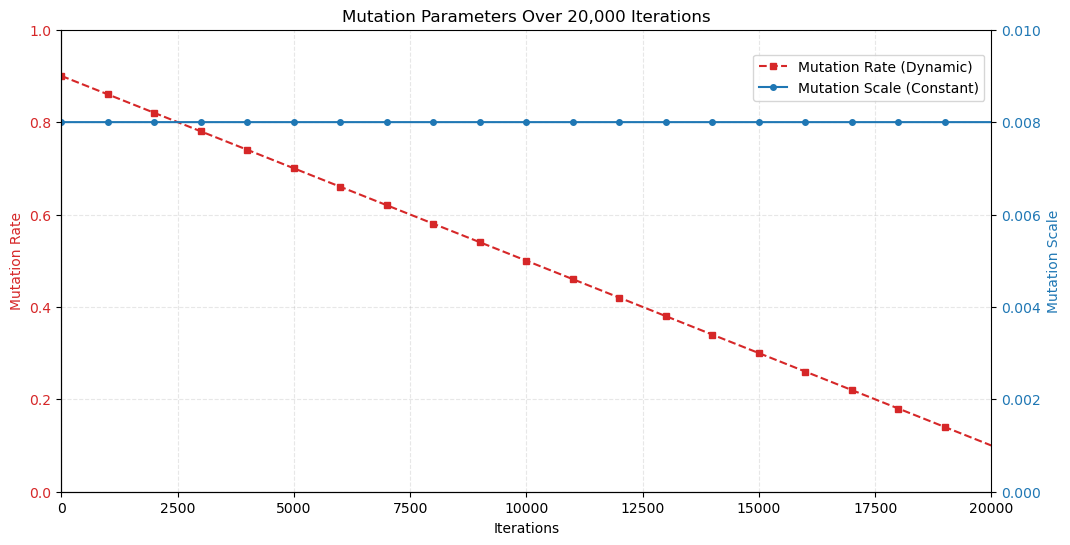

In [8]:
plot_mutation_parameters()

<h3 id="8-combining-two-offspring">8 - Combining two offspring </h3>

In [9]:
def merge_two_offs(off_params_1, off_params_2, off_layers_1, off_layers_2):
    """
    Merge off_layers_1 and off_layers_2, sort by Pareto rank and cost, select unique solutions,
    and update parameters based on their source.
    
    Returns:
    off_params -- Merged parameters dictionary
    off_layers -- Sorted list of unique solutions
    mask_trim -- Dictionary of masks indicating updated regions
    """
    # Merge off_layers_1 and off_layers_2 with source tags
    joined_layers  = []
    for entry in off_layers_1:
        joined_layers .append((entry, "1"))
    for entry in off_layers_2:
        joined_layers .append((entry, "2"))
    # Each element in joined_layers  is a tuple of the form: (solution, source)
    # Extract solutions [[layer_dims_1, cost_1], [layer_dims_2, cost_2]] for Pareto ranking (e.g., [[12288, 20, 5, 0.09], [12288, 17, 5, 0.07]).
    
    # Extract solutions for Pareto ranking
    # Each element in joined_layers  is a tuple of the form: (solution, source)
    # Extract solutions [[layer_dims_1, cost_1], [layer_dims_2, cost_2]] 
	# (e.g., [[12288, 20, 5, 0.09], [12288, 17, 5, 0.07]) for Pareto ranking.
    solutions = [entry[0] for entry in joined_layers ]
    
    # Compute Pareto ranks
    pareto_ranks = pareto_dominance_rank(solutions)
    
	# Sort joined_layers  by rank and cost
	# Pair each entry in joined_layers  with its corresponding Pareto rank
    ranked_entries = list(zip(pareto_ranks, joined_layers ))
    
	# Sort by Pareto rank (first element) and then by cost (last element of the entry)
	# Pareto Rank: (x[0]) The primary sorting criterion.
    # solution: (x[1][0])
	# Cost: (x[1][0][-1]) The secondary sorting criterion.
    # source: (x[1][1])
    sorted_joined_layers = sorted(
		ranked_entries,
		key=lambda x: (x[0], x[1][0][-1])  # (Pareto rank, cost)
	)

    # Unzip the sorted data to get the sorted joined_layers : ranks, solutions = zip(*sorted_joined_layers)
    # The result is a tuple of solution entries: (([12288, 17, 5, 0.07], "1"), ([12288, 20, 5, 0.09], "2"))
    _, sorted_joined_layers = zip(*sorted_joined_layers)
    # To make it easier to work with later in the code, convert it back to a list; because list is mutable.
    sorted_joined_layers = list(sorted_joined_layers)
    
    # Select unique solutions and update parameters
    seen = set()
    off_layers = []
    
     # Create a zero-initialized array with the same shape as parameter_1
    off_params = {}
    for key in off_params_1.keys():
        # Create a zero-initialized array with the same shape as parameter_old[key]
        off_params[key] = np.zeros_like(off_params_1[key])
        
    # Dictionary of masks indicating updated regions  
    mask_trim = {}
    for entry, source in sorted_joined_layers:
        layer_dims = tuple(entry[:-1])  # Extract layer_dims (exclude cost)
        if layer_dims not in seen:
            seen.add(layer_dims)
            off_layers.append(entry)
 
			# Trim parameters based on source
            if source == "2":
                trim_params = trim_parameters(off_params_2, layer_dims)
            else:
                trim_params = trim_parameters(off_params_1, layer_dims)
            
            # Update parameters and mask_trim
            for key in trim_params:
                # Update parameters

                if key not in mask_trim:
                    off_params[key][:trim_params[key].shape[0], :trim_params[key].shape[1]] = trim_params[key]
                    mask_trim[key] = np.zeros_like(off_params[key], dtype=bool)
                    mask_trim[key][:trim_params[key].shape[0], :trim_params[key].shape[1]] = True
                else:
                    off_params, mask_trim = merge_2_params(off_params, trim_params, mask_trim)
                    # Check stopping condition
        if len(off_layers) == len(off_layers_1):
            break  # Exit the loop when the condition is met

    if len(off_layers) < len(off_layers_1):
        raise TypeError(f"Warning: Only {len(off_layers)} unique architectures could be generated.")

    return off_params, off_layers, mask_trim
def merge_2_matrices(A, C, mask_B):
    """
    Merge matrix C into A, excluding the region defined by mask_B.
    
    Parameters:
        A (np.ndarray): The base matrix to be updated.
        C (np.ndarray): The matrix to merge into A.
        mask_B (np.ndarray): Boolean mask representing the region of B in A.

    Returns:
        A (np.ndarray): Updated matrix A after merging.
        mask_BC (np.ndarray): Combined boolean mask for regions of B and C.
    """
    # Get dimensions of C
    rows_C, cols_C = C.shape

    # Create a mask for the region of C
    mask_C = np.zeros_like(A, dtype=bool)
    mask_C[:rows_C, :cols_C] = True

    # Combine masks of B and C
    mask_BC = mask_B | mask_C

    # Replace elements of A with C, excluding the region of B
    valid_mask_C = ~mask_B[:rows_C, :cols_C]  # Mask for valid positions in C
    A[:rows_C, :cols_C][valid_mask_C] = C[valid_mask_C]

    return A, mask_BC
def merge_2_params(parameter_A, parameter_B, trim_mask):
    """
    Merge two sets of parameters (weights and biases) layer by layer.
    
    Arguments:
    parameter_A -- dictionary of parameters (weights and biases) for model A
    parameter_B -- dictionary of parameters (weights and biases) for model B
    trim_mask -- dictionary of boolean masks for each parameter in model A
    
    Returns:
    updated_parameter_A -- updated parameter dictionary for model A
    trim_mask_updated -- updated dictionary of boolean masks
    """
    # Initialize updated dictionaries
    trim_mask_updated = {}
    updated_parameter_A = deepcopy(parameter_A)  # Create a deep copy of parameter_A

    # Iterate over the keys in trim_mask
    for key in trim_mask.keys():
        # Ensure the key exists in both parameter_A and parameter_B
        if key not in parameter_A or key not in parameter_B:
            raise KeyError(f"Key '{key}' is missing in parameter_A or parameter_B.")
        
        # Ensure the values are NumPy arrays
        if not isinstance(parameter_A[key], np.ndarray) or not isinstance(parameter_B[key], np.ndarray):
            raise TypeError(f"Values for key '{key}' in parameter_A or parameter_B must be NumPy arrays.")
        if not isinstance(trim_mask[key], np.ndarray):
            raise TypeError(f"Value for key '{key}' in trim_mask must be a NumPy array.")
        
        # Merge weights or biases
        updated_parameter_A[key], trim_mask_updated[key] = \
            merge_2_matrices(updated_parameter_A[key], parameter_B[key], trim_mask[key])
    
    return updated_parameter_A, trim_mask_updated

In [10]:
# Example usage:
# Set seeds for reproducibility
np.random.seed(42)
random.seed(42)
# Parameters for offspring 1
off_params_1 = {
    "W1": np.random.rand(4, 4),
    "b1": np.random.rand(4, 1),
    "W2": np.random.rand(1, 4),
    "b2": np.random.rand(1, 1)
}
print("off_params_1:")
print(off_params_1)

# Parameters for offspring 2
off_params_2 = {
    "W1": np.random.rand(4, 4),
    "b1": np.random.rand(4, 1),
    "W2": np.random.rand(1, 4),
    "b2": np.random.rand(1, 1)
}
print("off_params_2:")
print(off_params_2)

# Layers for offspring 1
off_layers_1 = [[4, 1, 2, 0.029], [4, 3, 1, 0.03], [4, 2, 1, 0.035], [4, 4, 4, 0.032]]
# Layers for offspring 2
off_layers_2 = [[4, 1, 2, 0.025], [4, 2, 1, 0.034], [4, 3, 1, 0.035], [4, 4, 4, 0.036]]

off_layers_1_and_2 = [[4, 1, 2, 0.029], [4, 3, 1, 0.03], [4, 2, 1, 0.035], [4, 4, 4, 0.032], [4, 1, 2, 0.025], [4, 2, 1, 0.034], [4, 3, 1, 0.035], [4, 4, 4, 0.036]]

sorted_joined_layers, sorted_pareto_ranks = sort_by_pareto_rank_and_cost(off_layers_1_and_2)
print("sorted_joined_layers: ")
print(sorted_joined_layers)
print("sorted_pareto_ranks of sorted_joined_layers:")
print(sorted_pareto_ranks)

off_params, off_layers, mask_trim = merge_two_offs(off_params_1, off_params_2, off_layers_1, off_layers_2)
print("Selected Layers:")
print(off_layers)


print("Merged Parameters:")
print(off_params)

print("mask_trim:")
print(mask_trim)


off_params_1:
{'W1': array([[0.37454012, 0.95071431, 0.73199394, 0.59865848],
       [0.15601864, 0.15599452, 0.05808361, 0.86617615],
       [0.60111501, 0.70807258, 0.02058449, 0.96990985],
       [0.83244264, 0.21233911, 0.18182497, 0.18340451]]), 'b1': array([[0.30424224],
       [0.52475643],
       [0.43194502],
       [0.29122914]]), 'W2': array([[0.61185289, 0.13949386, 0.29214465, 0.36636184]]), 'b2': array([[0.45606998]])}
off_params_2:
{'W1': array([[0.78517596, 0.19967378, 0.51423444, 0.59241457],
       [0.04645041, 0.60754485, 0.17052412, 0.06505159],
       [0.94888554, 0.96563203, 0.80839735, 0.30461377],
       [0.09767211, 0.68423303, 0.44015249, 0.12203823]]), 'b1': array([[0.49517691],
       [0.03438852],
       [0.9093204 ],
       [0.25877998]]), 'W2': array([[0.66252228, 0.31171108, 0.52006802, 0.54671028]]), 'b2': array([[0.18485446]])}
sorted_joined_layers: 
[[4, 1, 2, 0.025], [4, 3, 1, 0.03], [4, 2, 1, 0.034], [4, 1, 2, 0.029], [4, 2, 1, 0.035], [4, 4, 4, 0.0

<h3 id="9-anabolism-process">8 - Anabolism Process </h3>

In [11]:
def anabolism_params(leader_params, follower_params, off_params, leader_layers, follower_layers, off_layers, max_layer_dims):
    """
    Merge and sort leader_layers, follower_layers, and off_layers by Pareto rank and cost.
    Update parameters for Leader and Follower based on sorted entries.
    
    Arguments:
    leader_params -- Parameters for Leader
    follower_params -- Parameters for Follower
    parameters_new -- New parameters
    leader_layers -- List of solutions for Leader
    follower_layers -- List of solutions for Follower
    off_layers -- List of new solutions
    
    Returns:
    updated_leader_layers -- Updated parameters for Leader
    updated_follower_layers -- Updated parameters for Follower
    updated_leader_layers -- Updated layers for Leader
    updated_follower_layers -- Updated layers for Follower
    """
    # Merge leader_layers, follower_layers, and off_layers with source tags
    joined_layers = []
    for entry in leader_layers:
        joined_layers.append((entry, "lead"))
    for entry in follower_layers:
        joined_layers.append((entry, "foll"))
    for entry in off_layers:
        joined_layers.append((entry, "off"))
        
    # Extract solutions for Pareto ranking
    # Each element in joined_layers is a tuple of the form: (solution, source)
    # Extract solutions [[layer_dims_1, cost_1], [layer_dims_2, cost_2]] 
	# (e.g., [[12288, 20, 5, 0.09], [12288, 17, 5, 0.07]) for Pareto ranking.
    solutions = [entry[0] for entry in joined_layers]  

    # Compute Pareto ranks
    pareto_ranks = pareto_dominance_rank(solutions)
    
	# Sort joined_layers by rank and cost
	# Pair each entry in joined_layers with its corresponding Pareto rank
    # Each element in ranked_entries is a tuple of the form: (Pareto_rank, (solution, source)) 
	# e.g., (1, ([12288, 20, 5, 0.09], "off"))
    ranked_entries = list(zip(pareto_ranks, joined_layers))

	# Sort by Pareto rank (first element) and then by cost (last element of the entry)
	# Pareto Rank: (x[0]) The primary sorting criterion.
    # solution: (x[1][0])
	# Cost: (x[1][0][-1]) The secondary sorting criterion.
    # source: (x[1][1])
    sorted_joined_layers = sorted(
		ranked_entries,
		key=lambda x: (x[0], x[1][0][-1])  # (Pareto rank, cost)
	)
    
	# Unzip the sorted data to get the sorted joined_layers: ranks, solutions = zip(*sorted_joined_layers)
    # The result is a tuple of solution entries: (([12288, 17, 5, 0.07], "lead"), ([12288, 20, 5, 0.09], "off"))
    _, sorted_joined_layers = zip(*sorted_joined_layers)
    
    # To make it easier to work with later in the code, convert it back to a list; because list is mutable.
    # The result is a list of solution entries: [([12288, 17, 5, 0.07], "lead"), ([12288, 20, 5, 0.09], "off")]
    sorted_joined_layers = list(sorted_joined_layers)
    
    # Select unique solutions and update parameters, layers
    seen_leader = set()
    seen_follower = set()
    updated_leader_layers = []
    updated_follower_layers = []
    mask_trim_leader = {}
    mask_trim_follower = {}
    updated_leader_params = deepcopy(leader_params)
    updated_follower_params = deepcopy(follower_params)

    def add_unique_solution(entry, layer_dims, target_agent, seen_set):
        '''
        Helper function to add a solution to the respective agent if it's unique.
        Its purpose is to avoid duplicates in the list of solutions. 
        '''
        if layer_dims not in seen_set:
            seen_set.add(layer_dims)  # Mark the solution as seen
            target_agent.append(entry)  # Add the solution to the target_agent
            return True  # Indicate success
        return False  # Indicate failure (duplicate)

    # Iterate through sorted_entries
    for idx, (entry, source) in enumerate(sorted_joined_layers):
        # Tuples are immutable, making them suitable for use as keys in sets or dictionaries.
        layer_dims = tuple(entry[:-1])  # Extract layer dimensions (exclude cost)
        
        # Trim parameters based on source
        if 	source == "lead":
            trim_params = trim_parameters(leader_params, layer_dims)
        elif source == "foll":
            trim_params = trim_parameters(follower_params, layer_dims)
        else:
            trim_params = trim_parameters(off_params, layer_dims)
        
        # Update leader_params and follower_params based on index
        if idx % 2 == 0:  # Even index → Leader
            if add_unique_solution(entry, layer_dims, updated_leader_layers, seen_leader):
                # Update parameters and mask_trim
                for key in trim_params:
                    if key not in mask_trim_leader:
                        updated_leader_params[key][:trim_params[key].shape[0], :trim_params[key].shape[1]] = trim_params[key]
                        # Create mask for the updated region
                        mask_trim_leader[key] = np.zeros_like(updated_leader_params[key], dtype=bool)
                        mask_trim_leader[key][:trim_params[key].shape[0], :trim_params[key].shape[1]] = True
                    else:
                        updated_leader_params, mask_trim_leader = merge_2_params(updated_leader_params, trim_params, mask_trim_leader)
            else:
                if add_unique_solution(entry, layer_dims, updated_follower_layers, seen_follower):
				# Update parameters and mask_trim
                    for key in trim_params:
                        if key not in mask_trim_follower:
                            updated_follower_params[key][:trim_params[key].shape[0], :trim_params[key].shape[1]] = trim_params[key]
                            # Create mask for the updated region
                            mask_trim_follower[key] = np.zeros_like(updated_follower_params[key], dtype=bool)
                            mask_trim_follower[key][:trim_params[key].shape[0], :trim_params[key].shape[1]] = True
                        else:
                            updated_follower_params, mask_trim_follower = merge_2_params(updated_follower_params, trim_params, mask_trim_follower)
        else:  # Odd index → Follower
            if add_unique_solution(entry, layer_dims, updated_follower_layers, seen_follower):
                # Update parameters and mask_trim
                for key in trim_params:
                    if key not in mask_trim_follower:
                        updated_follower_params[key][:trim_params[key].shape[0], :trim_params[key].shape[1]] = trim_params[key]
                        # Create mask for the updated region
                        mask_trim_follower[key] = np.zeros_like(updated_follower_params[key], dtype=bool)
                        mask_trim_follower[key][:trim_params[key].shape[0], :trim_params[key].shape[1]] = True
                    else:
                        updated_follower_params, mask_trim_follower = merge_2_params(updated_follower_params, trim_params, mask_trim_follower)
            else:
                if add_unique_solution(entry, layer_dims, updated_leader_layers, seen_leader):
					# Update parameters and mask_trim
                    for key in trim_params:
                        if key not in mask_trim_leader:
                            updated_leader_params[key][:trim_params[key].shape[0], :trim_params[key].shape[1]] = trim_params[key]
                            # Create mask for the updated region
                            mask_trim_leader[key] = np.zeros_like(updated_leader_params[key], dtype=bool)
                            mask_trim_leader[key][:trim_params[key].shape[0], :trim_params[key].shape[1]] = True
                        else:
                            updated_leader_params, mask_trim_leader = merge_2_params(updated_leader_params, trim_params, mask_trim_leader)
    
    # Ensure output sizes match original agent sizes
    while len(updated_follower_layers) < len(follower_layers):
        new_solution = create_new_solution(updated_follower_layers, CR, PAR, max_layer_dims)
        # new_solution = [12288, 20, 5, 1]
        new_solution.append(0.1) # The cost is initialized to 0.1 as a temporary value until the actual cost is calculated later.
        # new_solution = [12288, 20, 5, 1, 0.1]
        new_layer_dims = tuple(new_solution[:-1])
        add_unique_solution(new_solution, new_layer_dims, updated_follower_layers, seen_follower)
    while len(updated_leader_layers) < len(leader_layers):
        new_solution = create_new_solution(updated_leader_layers, CR, PAR, max_layer_dims)
        new_solution.append(0.1)
        new_layer_dims = tuple(new_solution[:-1])
        add_unique_solution(new_solution, new_layer_dims, updated_leader_layers, seen_leader)
    updated_follower_layers = updated_follower_layers[:len(follower_layers)]

    updated_leader_layers = updated_leader_layers[:len(leader_layers)]

    return updated_leader_params, updated_follower_params, updated_leader_layers, updated_follower_layers

def update_cost(agent_layers, agent_params, X, Y, lambd=0.0, keep_prob=1.0, training=True):
    """
    Update the cost values in agent_layers based on new parameters.  
    Returns:
    updated_agent_layers -- list of layer_dims with updated cost values.
    """
    updated_agent_layers = []  # Initialize the updated layers

    for i in range(len(agent_layers)):
        # Extract the layer dimensions from the current solution (excluding the cost)
        layer_dims = agent_layers[i][:-1]
        
        # Trim the parameters to match the current layer dimensions
        trimmed_params = trim_parameters(agent_params, layer_dims)
        
        # Perform forward propagation to calculate AL (activation of the output layer)
        AL = L_model_forward(X, trimmed_params, keep_prob=keep_prob, training=training)
        
        # Calculate the cost value
        new_cost = compute_cost(AL, Y, trimmed_params, lambd=lambd)
        
        # Create a new solution with updated cost
        updated_solution = agent_layers[i][:-1] + [new_cost]  # Keep the original dimensions and update the cost
        
        # Add the updated solution to the updated_agent_layers
        updated_agent_layers.append(updated_solution)
    
    return updated_agent_layers

def update_and_sort(agent_layers, agent_params, X, Y, lambd=0.0, keep_prob=1.0, training=True):
    # Update agent based on parameters and layers
    agent_layers = update_cost(agent_layers, agent_params, X, Y, lambd=lambd, keep_prob=keep_prob, training=training)
    # Sort agent based on Pareto rank and cost
    agent_layers, _ = sort_by_pareto_rank_and_cost(agent_layers)
    return agent_layers

def update_lead_foll(leader_params, follower_params, leader_layers, follower_layers, X, Y, lambd=0.0, keep_prob=1.0, training=True):
    # Update and sort leader_layers and follower_layers
    updated_leader_layers = update_and_sort(leader_layers, leader_params, X, Y, lambd=lambd, keep_prob=keep_prob, training=training)
    updated_follower_layers = update_and_sort(follower_layers, follower_params, X, Y, lambd=lambd, keep_prob=keep_prob, training=training)
    # Create deep copies of parameters
    updated_leader_params = deepcopy(leader_params)
    updated_follower_params = deepcopy(follower_params)
    # Compare costs between leader_layers and follower_layers
    if updated_follower_layers[0][-1] < updated_leader_layers[0][-1]:
 	# Swap parameters if follower_layers has a better cost
        updated_leader_params, updated_follower_params = updated_follower_params, updated_leader_params
    # Swap leader and follower
        updated_leader_layers, updated_follower_layers = updated_follower_layers, updated_leader_layers
        # print("Leader and Follower have changed")
        
    return updated_leader_params, updated_follower_params, updated_leader_layers, updated_follower_layers  


<h3 id="10-train-the-model">9 - Train the Model </h3>

In [12]:
def Dual_Individual_GA(size, max_iter, X, Y, max_layer_dims, stop_cost, lambd=0.0, keep_prob=1.0, training=True):

	"""
    Dual-GA Training Evaluation with L2 Regularization and Dropout.
    
    This function performs:
    1. Crossover and mutation to generate offspring
    2. Training phase evaluation (with Dropout ON, L2 ON)
    3. Testing phase evaluation (with Dropout OFF, L2 ON)
    4. Update Leader and Follower models
    
    Arguments:
    iteration -- current iteration number (for dynamic mutation rate)
    leader_params/follower_params -- current model parameters
    leader_layers/follower_layers -- current network architectures
    X, Y -- training data
    lambd -- L2 regularization hyperparameter
    keep_prob -- dropout keep probability
    max_layer_dims -- maximum layer dimensions
    training -- boolean, True for training mode (Dropout ON), False for testing
    
    Returns:
    Updated leader and follower parameters and layers
	"""

	leader_layers, leader_params = initialize_agent_network(size, X, Y, max_layer_dims)
	leader_layers, _ = sort_by_pareto_rank_and_cost(leader_layers)
	
	follower_layers, follower_params = initialize_agent_network(size, X, Y, max_layer_dims)
	follower_layers, _ = sort_by_pareto_rank_and_cost(follower_layers)
	
	best_costs_leader = []  # this is a list that tracks the minimum costs of leader_layers or follower_layers over time.
	best_costs_follower = []  

	for iteration in range(max_iter):
		
		if min([solution[-1] for solution in leader_layers]) < stop_cost:
			best_index = np.argmin([solution[-1] for solution in leader_layers])
			best_solution = leader_layers[best_index][:-1]  # Exclude the cost from the best solution
			print(f"Iteration {iteration}/{max_iter}, best_solution: {best_solution}, Best Cost: {leader_layers[best_index][-1]}")
	
			return best_solution, min([solution[-1] for solution in leader_layers]), \
					leader_params, follower_params, leader_layers, follower_layers, best_costs_leader, best_costs_follower

		# GENERATE OFFSPRING (Crossover & Mutation)
		# Compute mutation_scale and mutation_rate
		mutation_rate = linear_value(iteration, max_iter, min_val = 0.1, max_val = 0.9)
		mutation_scale = 0.008
		off_layers  = create_new_solutions(leader_layers, follower_layers, CR, PAR, max_layer_dims)

		off_params_1, off_params_2 = crossover_rows_vectorized(leader_params, follower_params)
		off_params_1 = mutate(off_params_1, mutation_rate, mutation_scale)
		off_params_2 = mutate(off_params_2, mutation_rate, mutation_scale)

		# EVALUATE INDIVIDUAL OFFSPRING (Training Phase, Dropout=ON)
		# Update costs of off_layers_1 and off_layers_2
		# Same architecture layers with off_layers, but different costs due to different parameter sets
		off_layers_1  = update_and_sort(off_layers, off_params_1, X, Y, lambd=lambd, keep_prob=keep_prob, training=training)
		off_layers_2 = update_and_sort(off_layers, off_params_2, X, Y, lambd=lambd, keep_prob=keep_prob, training=training)

		# Combine child1 and child2
		off_params, off_layers , _ = merge_two_offs(off_params_1, off_params_2, off_layers_1 , off_layers_2)
		off_layers  = update_and_sort(off_layers, off_params, X, Y, lambd=lambd, keep_prob=1.0, training=False)

		# UPDATE POPULATION (Dropout=OFF)
		# Update leader and Follower models
		leader_params, follower_params, leader_layers, follower_layers = anabolism_params(\
																							leader_params, follower_params, \
																							off_params, leader_layers, follower_layers, \
																							off_layers , max_layer_dims)
		
		leader_params, follower_params, leader_layers, follower_layers = update_lead_foll(leader_params, follower_params, \
																						leader_layers, follower_layers, X, Y, \
																						lambd=lambd, keep_prob=1.0, training=False)
		# best costs of leader and follower are recorded every 100 iterations.
		if iteration % 100 == 0:
			best_cost_leader = min([solution[-1] for solution in leader_layers])
			best_costs_leader.append(best_cost_leader)
			best_cost_follower = min([solution[-1] for solution in follower_layers])
			best_costs_follower.append(best_cost_follower)

		# Print the best cost at every 1000 iterations
		if iteration % 1000 == 0:
			best_cost = min([solution[-1] for solution in leader_layers])
			print(f"Iteration {iteration + 1}/{max_iter}, Best Cost: {best_cost}")

    
	best_index = np.argmin([solution[-1] for solution in leader_layers])
	best_solution = leader_layers[best_index][:-1]  # Exclude the cost from the best solution
	print(f"Iteration {iteration}/{max_iter}, best_solution: {best_solution}, Best Cost: {leader_layers[best_index][-1]}")

	return best_solution, min([solution[-1] for solution in leader_layers]),\
		  leader_params, follower_params, leader_layers, follower_layers, best_costs_leader, best_costs_follower


In [13]:
# This loop iterates over a range of indices (size) to process solutions from leader_layers and follower_layers, trim parameters from leader_params
# and follower_params, and generate predictions for both training and testing datasets. The prediction function is provided by the course.
def process_leader_follower(leader_layers, follower_layers, leader_params, follower_params, train_x, train_y, test_x, test_y, size):
    """
    Process leader and follower layers to generate predictions for training and testing datasets.

    Args:
        leader_layers (list): List of leader layer configurations.
        follower_layers (list): List of follower layer configurations.
        leader_params (dict): Global parameters for the leader.
        follower_params (dict): Global parameters for the follower.
        train_x (ndarray): Training input data.
        train_y (ndarray): Training labels.
        test_x (ndarray): Testing input data.
        test_y (ndarray): Testing labels.
        size (int): Number of iterations (size of leader_layers and follower_layers).

    Returns:
        None
    """
    # Print leader and follower layers
    print("leader_layers:")
    for layer in leader_layers:
        print(layer)

    print("\nfollower_layers:")
    for layer in follower_layers:
        print(layer)

    # General description of the process
    print("\nTrimming the global parameters (leader_params and follower_params) to match the architecture of each solution."
          "\nGenerating predictions for both training and testing datasets.\n")

    # Iterate through each solution
    for i in range(size):
        print(f"Iteration {i + 1}/{size}")

        # Leader processing
        print(f"Leader architecture: {leader_layers[i][:-1]}")
        trimmed_leader_params = trim_parameters(leader_params, leader_layers[i][:-1])
        print("Training Predictions (Leader):")
        predictions_train_leader = predict_results(train_x, train_y, trimmed_leader_params)
        print("Testing Predictions (Leader):")
        predictions_test_leader = predict_results(test_x, test_y, trimmed_leader_params)
        print()

        # Follower processing
		
        print(f"Follower architecture: {follower_layers[i][:-1]}")
        trimmed_follower_params = trim_parameters(follower_params, follower_layers[i][:-1])
        print("Training Predictions (Follower):")
        predictions_train_follower = predict_results(train_x, train_y, trimmed_follower_params)
        print("Testing Predictions (Follower):")
        predictions_test_follower = predict_results(test_x, test_y, trimmed_follower_params)
        print()
	

In [14]:
# Set seeds for reproducibility
np.random.seed(42)
random.seed(42)

train_x_orig, train_y, test_x_orig, test_y, classes = load_data()
# Explore the dataset 
m_train = train_x_orig.shape[0]
num_px = train_x_orig.shape[1]
m_test = test_x_orig.shape[0]

print ("Number of training examples: " + str(m_train))
print ("Number of testing examples: " + str(m_test))
print ("Each image is of size: (" + str(num_px) + ", " + str(num_px) + ", 3)")
print ("train_x_orig shape: " + str(train_x_orig.shape))
print ("train_y shape: " + str(train_y.shape))
print ("test_x_orig shape: " + str(test_x_orig.shape))
print ("test_y shape: " + str(test_y.shape))

# Reshape the training and test examples 
train_x_flatten = train_x_orig.reshape(train_x_orig.shape[0], -1).T   # The "-1" makes reshape flatten the remaining dimensions
test_x_flatten = test_x_orig.reshape(test_x_orig.shape[0], -1).T

# Standardize data to have feature values between 0 and 1.
train_x = train_x_flatten/255.
test_x = test_x_flatten/255.
X = train_x
Y = train_y
print ("train_x's shape: " + str(train_x.shape))
print ("test_x's shape: " + str(test_x.shape))

Number of training examples: 209
Number of testing examples: 50
Each image is of size: (64, 64, 3)
train_x_orig shape: (209, 64, 64, 3)
train_y shape: (1, 209)
test_x_orig shape: (50, 64, 64, 3)
test_y shape: (1, 50)
train_x's shape: (12288, 209)
test_x's shape: (12288, 50)


Iteration 1/20000, Best Cost: 0.6928350810885712
Iteration 1001/20000, Best Cost: 0.29049581522720924
Iteration 2001/20000, Best Cost: 0.12709863269097085
Iteration 3001/20000, Best Cost: 0.06806367640537643
Iteration 4001/20000, Best Cost: 0.03859777985949124
Iteration 5001/20000, Best Cost: 0.025161274569665812
Iteration 5759/20000, best_solution: [12288, 7, 1], Best Cost: 0.014963891237613552
Best Layer Dimensions v1_1: [12288, 7, 1]
Best Cost v1_1 : 0.014963891237613552
leader_layers : [[12288, 7, 1, 0.014963891237613552], [12288, 6, 1, 0.017448720486963918], [12288, 5, 1, 0.031417808051239546], [12288, 3, 1, 0.03341989836781776], [12288, 1, 1, 0.6508359664308078]]
follower_layers : [[12288, 7, 1, 0.015082074420678784], [12288, 6, 1, 0.017448720486963918], [12288, 4, 1, 0.032271490567984625], [12288, 3, 1, 0.03341989836781776], [12288, 1, 1, 0.6508359664308078]]
leader_layers:
[12288, 7, 1, 0.014963891237613552]
[12288, 6, 1, 0.017448720486963918]
[12288, 5, 1, 0.031417808051239546

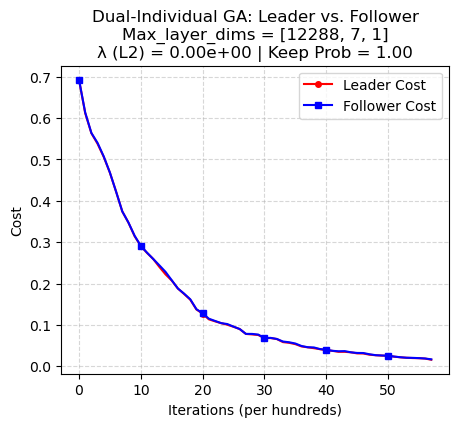

In [15]:
# Set seeds for reproducibility
import random
np.random.seed(42)
random.seed(42)

max_layer_dims = [12288, 7, 1]  # Initial max layer dimensions
size = 5  # Size of agent_layers
max_iter = 20000  # Number of iterations
CR = 0.9  # Consideration Rate
PAR = 0.3  # Pitch Adjustment Rate
stop_cost = 0.015
lamb = 0.0
keep_pro= 1

best_solution, best_cost, leader_params, follower_params, leader_layers, follower_layers, \
    best_costs_leader, best_costs_follower = Dual_Individual_GA(size, max_iter, X, Y, max_layer_dims, stop_cost, lambd=lamb, keep_prob=keep_pro, training=False)

# Print results
print("Best Layer Dimensions v1_1:", best_solution)
print("Best Cost v1_1 :", best_cost)
print("leader_layers :", leader_layers)
print("follower_layers :", follower_layers)
process_leader_follower(leader_layers, follower_layers, leader_params, follower_params, train_x, train_y, test_x, test_y, size)
plot_costs(best_costs_leader, best_costs_follower, max_layer_dims, lambd=lamb, keep_prob=keep_pro)